# Clustering enzymów EC 1–7 z ESM-2

Pipeline: FASTA → kontrola jakości → zbalansowana próbka → embeddingi ESM-2 → K-Means / HDBSCAN → PCA / UMAP → ewaluacja. **Etykiety EC nie są wykorzystywane do trenowania embeddingów ani klastrowania** (poza wyborem zbalansowanej próbki). Pierwszy eksperyment: maks. 1000 sekwencji/klasę. RTX 3050 Ti: mały model ESM-2 8M i batch=4. Przy kolejnych uruchomieniach embeddingi są odczytywane z cache.

**Uwaga:** dane nie zostały dołączone do notebooka; pliki są odczytywane lokalnie. Zależnie od wersji Transformers może być konieczne dopasowanie wersji pakietu.

In [1]:
from pathlib import Path
import re, random, hashlib, json
import numpy as np
import pandas as pd
import torch
from Bio import SeqIO
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
DATA_DIR = Path('data') if Path('data').is_dir() else Path(r'C:\Dev\BIO\data')
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
MAX_PER_CLASS = 1000  # None = wszystkie (znacznie wolniej)
MAX_RESIDUES = 1022  # ESM-2: 1024 tokeny łącznie z BOS/EOS
MODEL_NAME = 'facebook/esm2_t6_8M_UR50D'
BATCH_SIZE = 4
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Data:', DATA_DIR.resolve(), 'Device:', DEVICE)
if DEVICE == 'cuda': print(torch.cuda.get_device_name(0))

Data: C:\Dev\BIO\data Device: cpu


c:\Dev\BIO\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Wczytanie FASTA i kontrola danych

Odrzucamy sekwencje puste, z niedozwolonymi znakami i dłuższe niż limit modelu — **nie obcinamy** białek, żeby nie zgubić domen katalitycznych. Litery U/O/B/Z/X dopuszczamy, ale zamieniamy na X przed tokenizacją (model ESM obsługuje X). Pliki UniProt mogą zawierać ten sam rekord w więcej niż jednej klasie EC; takie konflikty usuwamy.

In [2]:
files = sorted(DATA_DIR.glob('uniprotkb_ec_*_AND_reviewed_true_*.fasta'))
assert len(files) == 7, f'Oczekiwano 7 plików FASTA, znaleziono {len(files)}: {files}'
records = []
for path in files:
    match = re.search(r'uniprotkb_ec_([1-7])_AND_', path.name)
    if not match: continue
    ec_class = int(match.group(1))
    count = 0
    for rec in SeqIO.parse(path, 'fasta'):
        seq = str(rec.seq).upper().replace(' ', '')
        records.append({'id': rec.id, 'sequence': seq, 'ec_class': ec_class, 'length': len(seq)})
        count += 1
    print(f'EC {ec_class}: {count:,} sekwencji')
df = pd.DataFrame(records)
print('Łącznie:', len(df))
display(df.groupby('ec_class').agg(n=('id','size'), median_length=('length','median')))

EC 1: 36,375 sekwencji
EC 2: 98,759 sekwencji
EC 3: 65,888 sekwencji
EC 4: 26,883 sekwencji
EC 5: 16,951 sekwencji
EC 6: 28,259 sekwencji
EC 7: 14,982 sekwencji
Łącznie: 288097


,n,median_length
ec_class,,
1,36375,351.0
2,98759,341.0
3,65888,323.0
4,26883,320.0
5,16951,361.0
6,28259,476.0
7,14982,348.0


In [3]:
# Konflikty: ta sama sekwencja przypisana do różnych klas → wyklucz
allowed = set('ACDEFGHIKLMNPQRSTVWYUBZOX')
valid = df['sequence'].map(lambda s: bool(s) and len(s) <= MAX_RESIDUES and set(s) <= allowed)
df = df.loc[valid].copy()
conflicting = df.groupby('sequence')['ec_class'].nunique()
conflicting_sequences = set(conflicting[conflicting > 1].index)
print('Sekwencje wieloklasowe (usunięte):', len(conflicting_sequences))
df = df[~df['sequence'].isin(conflicting_sequences)]
# identyczne sekwencje reprezentujemy tylko raz
df = df.drop_duplicates(subset=['sequence']).copy()
df['model_sequence'] = df['sequence'].str.replace(r'[UBZO]', 'X', regex=True)
print('Po filtracji:', len(df))
display(df['ec_class'].value_counts().sort_index())

Sekwencje wieloklasowe (usunięte): 5405
Po filtracji: 223794


ec_class
1    29587
2    76040
3    49770
4    20038
5    13063
6    23088
7    12208
Name: count, dtype: int64

## 2. Reprodukowalne próbkowanie

Balansujemy liczbę przykładów między klasami (bez duplikatów). Dla pełnego eksperymentu ustaw `MAX_PER_CLASS = None`. Przy mocno różnych liczebnościach wybieramy najmniejszą klasę jako limit.

In [4]:
sizes = df['ec_class'].value_counts()
n_per_class = int(sizes.min()) if MAX_PER_CLASS is None else min(MAX_PER_CLASS, int(sizes.min()))
sample = (df.groupby('ec_class', group_keys=False)
          .sample(n=n_per_class, random_state=SEED)
          .sort_values(['ec_class','id']).reset_index(drop=True))
print('Próbka:', len(sample), '(', n_per_class, 'na klasę)')
display(sample[['id','ec_class','length']].head())

Próbka: 7000 ( 1000 na klasę)


,id,ec_class,length
0,sp|A0A075TR41|PATJ_PENEN,1,326
1,sp|A0A0A1VAM4|USTC_USTVR,1,488
2,sp|A0A0B4GT47|ARP2_METAF,1,267
3,sp|A0A0E0RXA7|FSL5_GIBZE,1,359
4,sp|A0A0E3D8L2|PENL_PENCR,1,204


## 3. ESM-2: embeddingi per białko

Mean pooling tylko po aminokwasach (bez BOS/EOS i paddingu). Zapis do cache jest zależny od modelu i wybranych sekwencji. Dla RTX 3050 Ti używamy batch=4 i `torch.inference_mode()`. Jeśli wystąpi CUDA OOM, zmniejsz `BATCH_SIZE` do 1–2.

In [5]:
from transformers import AutoTokenizer, AutoModel

fingerprint = hashlib.sha256((MODEL_NAME + '\n' + '\n'.join(sample['model_sequence'])).encode()).hexdigest()[:16]
cache_file = OUTPUT_DIR / f'esm2_embeddings_{fingerprint}.npz'
if cache_file.exists():
    X = np.load(cache_file)['X']
    print('Załadowano cache:', cache_file)
else:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE).eval()
    vectors = []
    for start in tqdm(range(0, len(sample), BATCH_SIZE), desc='ESM-2'):
        seqs = sample['model_sequence'].iloc[start:start+BATCH_SIZE].tolist()
        batch = tokenizer(seqs, padding=True, return_tensors='pt', add_special_tokens=True)
        batch = {k: v.to(DEVICE) for k,v in batch.items()}
        with torch.inference_mode():
            hidden = model(**batch).last_hidden_state
        # ESM tokenizer: BOS na pozycji 0, EOS po ostatniej reszcie
        for j, seq in enumerate(seqs):
            vectors.append(hidden[j, 1:1+len(seq)].mean(dim=0).float().cpu().numpy())
    X = np.stack(vectors).astype(np.float32)
    np.savez_compressed(cache_file, X=X)
    del model
    if DEVICE == 'cuda': torch.cuda.empty_cache()
    print('Zapisano:', cache_file)
print('Embeddingi:', X.shape)
assert X.shape[0] == len(sample) and np.isfinite(X).all()

c:\Dev\BIO\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\mkowa\.cache\huggingface\hub\models--facebook--esm2_t6_8M_UR50D. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Dev\BIO\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses syml

Zapisano: outputs\esm2_embeddings_927071f4384be30d.npz
Embeddingi: (7000, 320)


## 4. Klastrowanie w oryginalnej przestrzeni embeddingów

Normalizacja L2, K-Means z `k=7` jako test zgodności z głównymi klasami EC. HDBSCAN automatycznie wyznacza liczbę klastrów i może oznaczyć część sekwencji jako szum (`-1`).

In [6]:
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, homogeneity_score

Xn = normalize(X)
y = sample['ec_class'].to_numpy()
kmeans = KMeans(n_clusters=7, random_state=SEED, n_init=20)
km_labels = kmeans.fit_predict(Xn)
hdb = HDBSCAN(min_cluster_size=30, min_samples=10)
hdb_labels = hdb.fit_predict(Xn)
sample['kmeans_cluster'] = km_labels
sample['hdbscan_cluster'] = hdb_labels

def metrics(name, labels):
    mask = labels != -1
    return {'method': name, 'clusters': len(set(labels[mask])),
            'noise_pct': round(100 * (1-mask.mean()), 2),
            'ARI_all': adjusted_rand_score(y, labels),
            'NMI_all': normalized_mutual_info_score(y, labels),
            'homogeneity_all': homogeneity_score(y, labels)}
results = pd.DataFrame([metrics('KMeans', km_labels), metrics('HDBSCAN', hdb_labels)])
display(results)
print('Uwaga: ARI/NMI dla HDBSCAN traktują -1 jako wspólny klaster szumu.')

c:\Dev\BIO\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,method,clusters,noise_pct,ARI_all,NMI_all,homogeneity_all
0,KMeans,7,0.0,0.041407,0.125750,0.117947
1,HDBSCAN,16,41.5,0.057059,0.213015,0.182017


Uwaga: ARI/NMI dla HDBSCAN traktują -1 jako wspólny klaster szumu.


## 5. PCA i UMAP — tylko wizualizacja

Wykresy kolorowane **prawdziwą klasą EC** oraz wynikiem K-Means. UMAP jest stochastyczny; jego odległości 2D nie są dowodem bliskości biologicznej.

c:\Dev\BIO\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


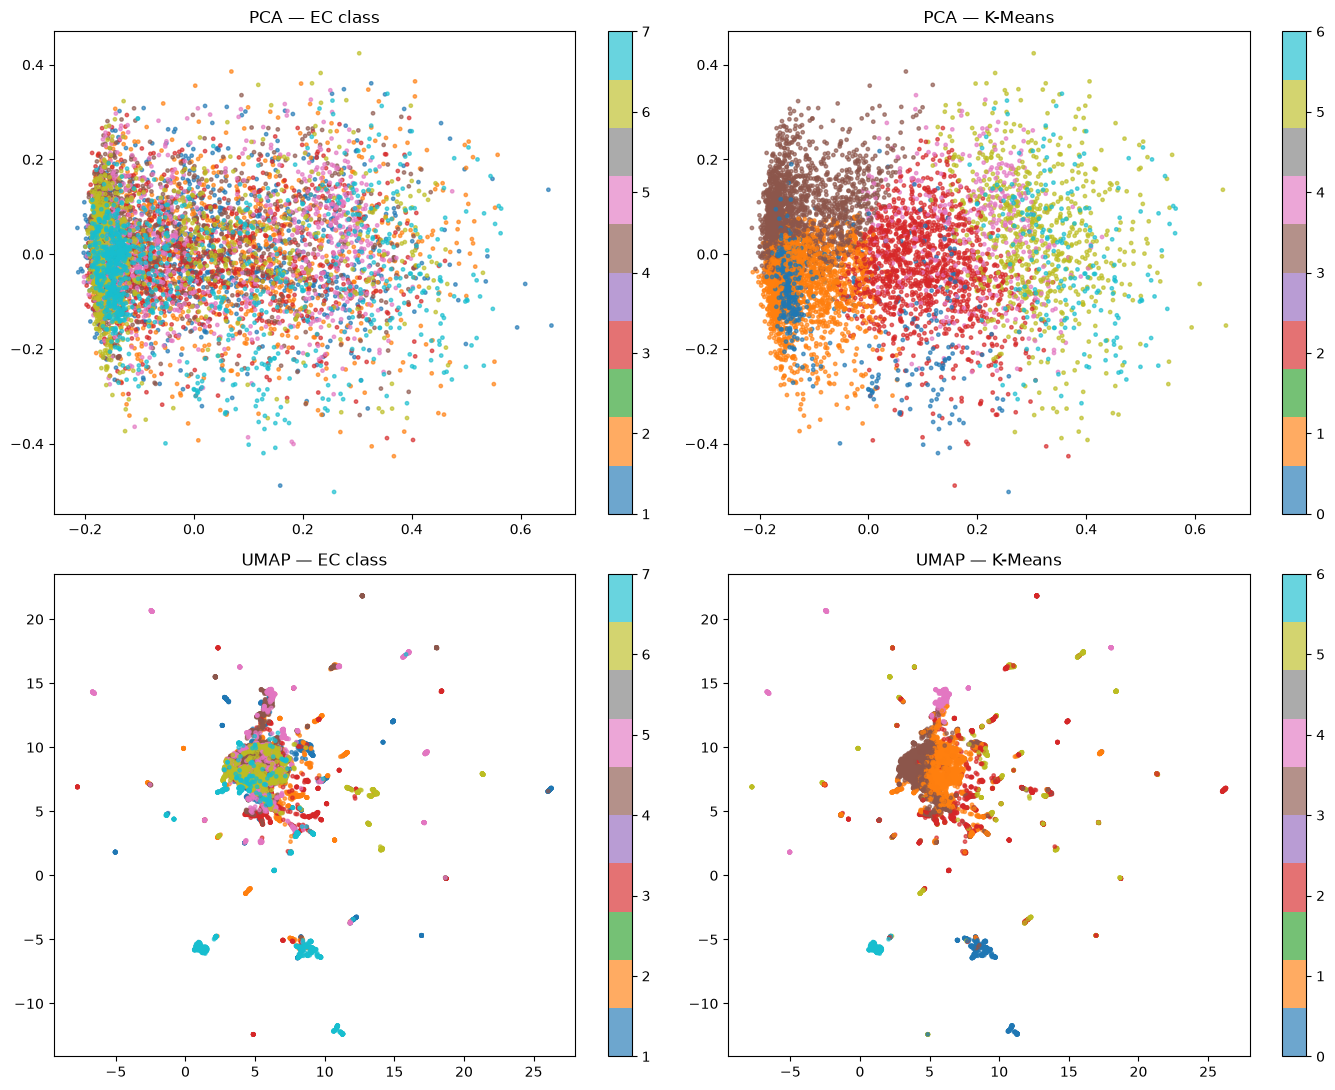

In [7]:
from sklearn.decomposition import PCA
import umap
import matplotlib.pyplot as plt

pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(Xn)
umap_2d = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1,
                        metric='cosine', random_state=SEED).fit_transform(Xn)
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for row, (coords, title) in enumerate([(pca_2d, 'PCA'), (umap_2d, 'UMAP')]):
    for col, (labels, name) in enumerate([(y, 'EC class'), (km_labels, 'K-Means')]):
        sc = axes[row, col].scatter(coords[:,0], coords[:,1], c=labels, cmap='tab10', s=6, alpha=.65)
        axes[row, col].set_title(f'{title} — {name}')
        fig.colorbar(sc, ax=axes[row, col])
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'clustering_pca_umap.png', dpi=160)
plt.show()

## 6. Analiza składu klastrów i zapis wyników

ec_class,1,2,3,4,5,6,7
kmeans_cluster,,,,,,,
0,30,54,21,2,3,0,339
1,254,248,285,324,336,397,228
2,297,293,280,95,115,146,69
3,252,211,268,379,236,345,151
4,45,10,14,158,174,0,0
5,122,183,132,42,136,112,7
6,0,1,0,0,0,0,206


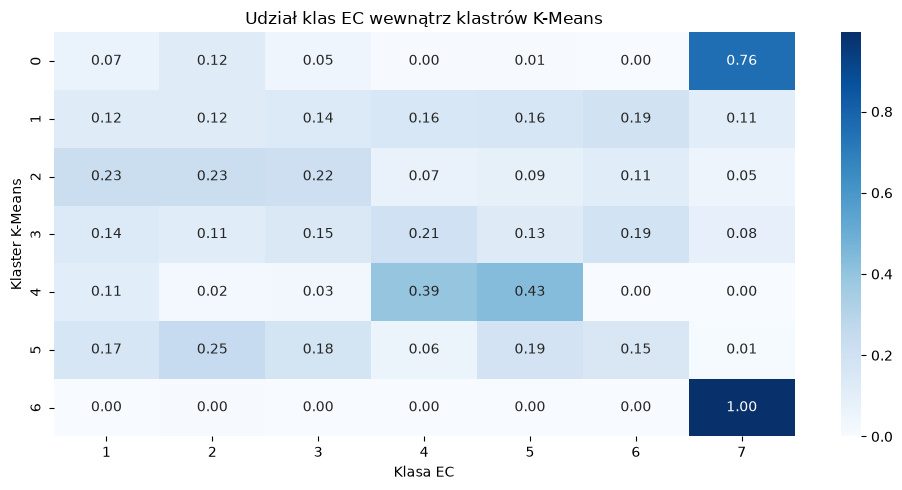

Wyniki zapisane w: C:\Dev\BIO\outputs


In [8]:
import seaborn as sns
composition = pd.crosstab(sample['kmeans_cluster'], sample['ec_class'])
display(composition)
plt.figure(figsize=(10, 5))
sns.heatmap(composition.div(composition.sum(axis=1), axis=0), annot=True, fmt='.2f', cmap='Blues')
plt.title('Udział klas EC wewnątrz klastrów K-Means')
plt.xlabel('Klasa EC'); plt.ylabel('Klaster K-Means')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'cluster_composition.png', dpi=160)
plt.show()
sample.drop(columns=['model_sequence']).to_csv(OUTPUT_DIR / 'sample_clusters.csv', index=False)
results.to_csv(OUTPUT_DIR / 'metrics.csv', index=False)
np.save(OUTPUT_DIR / 'embedding_matrix.npy', X)
print('Wyniki zapisane w:', OUTPUT_DIR.resolve())

Starting t-SNE for 7000 proteins...
PCA preprocessing done: 0.0s
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 7000 samples in 0.002s...
[t-SNE] Computed neighbors for 7000 samples in 0.131s...
[t-SNE] Computed conditional probabilities for sample 1000 / 7000
[t-SNE] Computed conditional probabilities for sample 2000 / 7000
[t-SNE] Computed conditional probabilities for sample 3000 / 7000
[t-SNE] Computed conditional probabilities for sample 4000 / 7000
[t-SNE] Computed conditional probabilities for sample 5000 / 7000
[t-SNE] Computed conditional probabilities for sample 6000 / 7000
[t-SNE] Computed conditional probabilities for sample 7000 / 7000
[t-SNE] Mean sigma: 0.080394
[t-SNE] KL divergence after 250 iterations with early exaggeration: 83.287560
[t-SNE] KL divergence after 1000 iterations: 1.324280
t-SNE completed in 18.9s


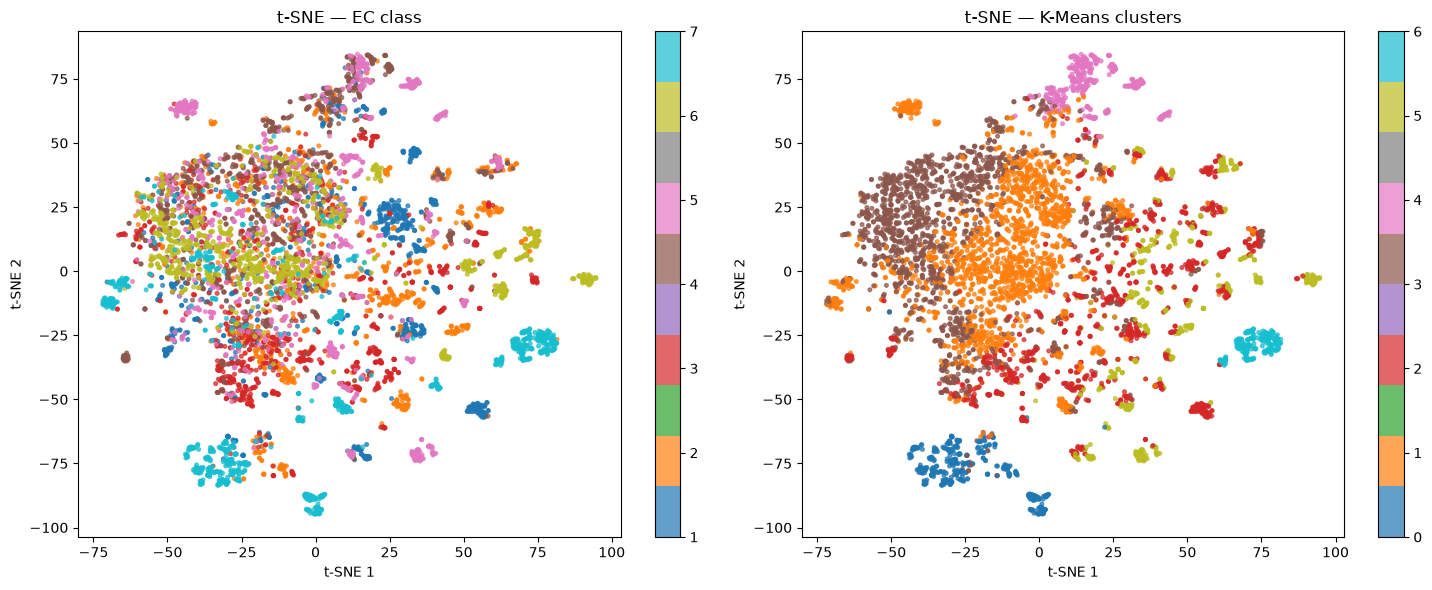

Saved: clustering_tsne.png, tsne_2d.npy


In [9]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
import time

start = time.perf_counter()

print(f"Starting t-SNE for {Xn.shape[0]} proteins...", flush=True)

n_pca = min(50, Xn.shape[1], Xn.shape[0])

X_pca = PCA(
    n_components=n_pca,
    random_state=SEED
).fit_transform(Xn)

print(f"PCA preprocessing done: {time.perf_counter()-start:.1f}s", flush=True)

# 2. t-SNE: 50D -> 2D
tsne = TSNE(
    n_components=2,
    perplexity=min(30, (len(Xn) - 1) / 3),
    learning_rate="auto",
    init="pca",
    max_iter=1000,
    random_state=SEED,
    verbose=1
)

tsne_2d = tsne.fit_transform(X_pca)

print(f"t-SNE completed in {time.perf_counter()-start:.1f}s", flush=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, labels, title in zip(
    axes,
    [y, km_labels],
    ["t-SNE — EC class", "t-SNE — K-Means clusters"]
):
    sc = ax.scatter(
        tsne_2d[:, 0],
        tsne_2d[:, 1],
        c=np.asarray(labels, dtype=int),
        cmap="tab10",
        s=7,
        alpha=0.7,
        rasterized=True
    )

    ax.set_title(title)
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    fig.colorbar(sc, ax=ax)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "clustering_tsne.png", dpi=160)
plt.show()

np.save(OUTPUT_DIR / "tsne_2d.npy", tsne_2d)

print("Saved: clustering_tsne.png, tsne_2d.npy")

Proteins: 7000
Embedding dimensions: 320
PCA finished: 0.0s
Selected 200/1400
Selected 400/1400
Selected 600/1400
Selected 800/1400
Selected 1000/1400
Selected 1200/1400
MaxMin split finished: 1.5s
Train: 5600
Test:  1400


Split,Test,Train,Total
EC class,,,
1,236,764,1000
2,302,698,1000
3,326,674,1000
4,179,821,1000
5,163,837,1000
6,96,904,1000
7,98,902,1000


[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 7000 samples in 0.001s...
[t-SNE] Computed neighbors for 7000 samples in 0.110s...
[t-SNE] Computed conditional probabilities for sample 1000 / 7000
[t-SNE] Computed conditional probabilities for sample 2000 / 7000
[t-SNE] Computed conditional probabilities for sample 3000 / 7000
[t-SNE] Computed conditional probabilities for sample 4000 / 7000
[t-SNE] Computed conditional probabilities for sample 5000 / 7000
[t-SNE] Computed conditional probabilities for sample 6000 / 7000
[t-SNE] Computed conditional probabilities for sample 7000 / 7000
[t-SNE] Mean sigma: 0.271496
[t-SNE] KL divergence after 250 iterations with early exaggeration: 82.195541
[t-SNE] KL divergence after 1000 iterations: 1.275168
t-SNE finished: 17.9s


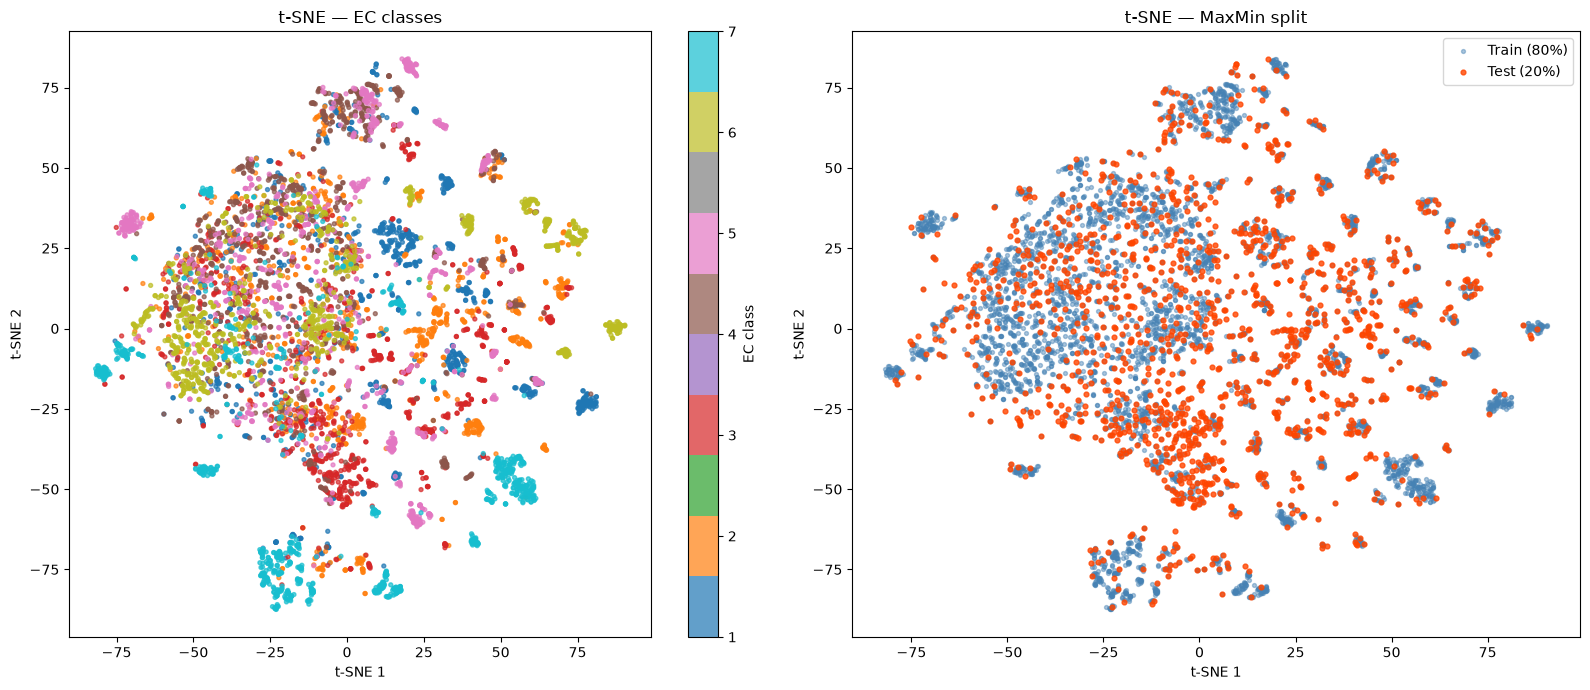

Saved results to: outputs


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import pairwise_distances

# ==========================================
# 1. Konfiguracja
# ==========================================

TEST_SIZE = 0.20
RANDOM_STATE = SEED
MAXMIN_PCA_DIM = 50

output_dir = Path(OUTPUT_DIR)
output_dir.mkdir(parents=True, exist_ok=True)

X = np.asarray(Xn, dtype=np.float32)
labels = np.asarray(y)

assert len(X) == len(labels)
assert len(X) >= 10

rng = np.random.default_rng(RANDOM_STATE)

print(f"Proteins: {len(X)}")
print(f"Embedding dimensions: {X.shape[1]}")

# ==========================================
# 2. PCA dla przyspieszenia
# ==========================================

start = time.perf_counter()

n_components = min(
    MAXMIN_PCA_DIM,
    X.shape[1],
    X.shape[0] - 1
)

X_reduced = PCA(
    n_components=n_components,
    random_state=RANDOM_STATE
).fit_transform(X)

# Normalizacja L2 do odległości cosinusowej
norms = np.linalg.norm(X_reduced, axis=1, keepdims=True)
X_reduced = X_reduced / np.maximum(norms, 1e-12)

print(f"PCA finished: {time.perf_counter()-start:.1f}s")

# ==========================================
# 3. MaxMin split
# ==========================================

def maxmin_split(X, test_size=0.2, seed=42):
    """
    Greedy MaxMin selection.

    Wybiera punkty możliwie oddalone od
    już wybranych punktów.

    Uwaga: jest to podział oparty na różnorodności
    embeddingów, a nie na homologii sekwencji.
    """

    rng = np.random.default_rng(seed)

    n = len(X)
    n_test = max(1, int(round(n * test_size)))

    # Pierwszy punkt losowy
    first = int(rng.integers(n))

    selected = np.empty(n_test, dtype=int)
    selected[0] = first

    # Odległość od najbliższego wybranego punktu
    min_distances = pairwise_distances(
        X,
        X[[first]],
        metric="euclidean"
    ).ravel()

    min_distances[first] = -np.inf

    for i in range(1, n_test):

        next_idx = int(np.argmax(min_distances))
        selected[i] = next_idx

        new_distances = pairwise_distances(
            X,
            X[[next_idx]],
            metric="euclidean"
        ).ravel()

        min_distances = np.minimum(
            min_distances,
            new_distances
        )

        min_distances[selected[:i+1]] = -np.inf

        if i % 200 == 0:
            print(f"Selected {i}/{n_test}", flush=True)

    test_idx = np.sort(selected)

    mask = np.ones(n, dtype=bool)
    mask[test_idx] = False

    train_idx = np.flatnonzero(mask)

    return train_idx, test_idx


start = time.perf_counter()

train_idx, test_idx = maxmin_split(
    X_reduced,
    test_size=TEST_SIZE,
    seed=RANDOM_STATE
)

print(f"MaxMin split finished: {time.perf_counter()-start:.1f}s")
print(f"Train: {len(train_idx)}")
print(f"Test:  {len(test_idx)}")

# ==========================================
# 4. Rozkład klas EC
# ==========================================

split_labels = np.full(len(X), "Train", dtype=object)
split_labels[test_idx] = "Test"

distribution = pd.crosstab(
    pd.Series(labels, name="EC class"),
    pd.Series(split_labels, name="Split")
)

distribution["Total"] = distribution.sum(axis=1)

display(distribution)

# ==========================================
# 5. t-SNE dla całego zbioru
# ==========================================

start = time.perf_counter()

tsne = TSNE(
    n_components=2,
    perplexity=min(30, (len(X) - 1) / 3),
    learning_rate="auto",
    init="pca",
    max_iter=1000,
    random_state=RANDOM_STATE,
    verbose=1
)

tsne_2d = tsne.fit_transform(X_reduced)

print(f"t-SNE finished: {time.perf_counter()-start:.1f}s")

# ==========================================
# 6. Wizualizacja
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Lewy wykres: EC classes
sc = axes[0].scatter(
    tsne_2d[:, 0],
    tsne_2d[:, 1],
    c=labels.astype(int),
    cmap="tab10",
    s=8,
    alpha=0.7
)

axes[0].set_title("t-SNE — EC classes")
axes[0].set_xlabel("t-SNE 1")
axes[0].set_ylabel("t-SNE 2")

fig.colorbar(sc, ax=axes[0], label="EC class")

# Prawy wykres: Train / Test
axes[1].scatter(
    tsne_2d[train_idx, 0],
    tsne_2d[train_idx, 1],
    c="steelblue",
    s=8,
    alpha=0.45,
    label="Train (80%)"
)

axes[1].scatter(
    tsne_2d[test_idx, 0],
    tsne_2d[test_idx, 1],
    c="orangered",
    s=12,
    alpha=0.8,
    label="Test (20%)"
)

axes[1].set_title("t-SNE — MaxMin split")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    output_dir / "tsne_maxmin_split.png",
    dpi=180
)

plt.show()

# ==========================================
# 7. Zapis podziału
# ==========================================

np.savez_compressed(
    output_dir / "maxmin_split.npz",
    train_idx=train_idx,
    test_idx=test_idx,
    tsne_2d=tsne_2d
)

split_df = pd.DataFrame({
    "index": np.arange(len(X)),
    "ec_class": labels,
    "split": split_labels,
    "tsne_x": tsne_2d[:, 0],
    "tsne_y": tsne_2d[:, 1]
})

split_df.to_csv(
    output_dir / "maxmin_split.csv",
    index=False
)

print("Saved results to:", output_dir)

MaxMin split:
  Train: 5600 | Test: 1400

Random stratified split:
  Train: 5600 | Test: 1400


,Method,EC class,Train,Test,Test %
0,MaxMin,1,764,236,16.857143
1,MaxMin,2,698,302,21.571429
2,MaxMin,3,674,326,23.285714
3,MaxMin,4,821,179,12.785714
4,MaxMin,5,837,163,11.642857
5,MaxMin,6,904,96,6.857143
6,MaxMin,7,902,98,7.000000
7,Random,1,800,200,14.285714
8,Random,2,800,200,14.285714
9,Random,3,800,200,14.285714



Train-Test distance comparison:


,Method,Mean distance,Median distance,Min distance,P10 distance
0,MaxMin,0.528916,0.542416,0.015776,0.287085
1,Random,0.376973,0.373204,0.007765,0.152850


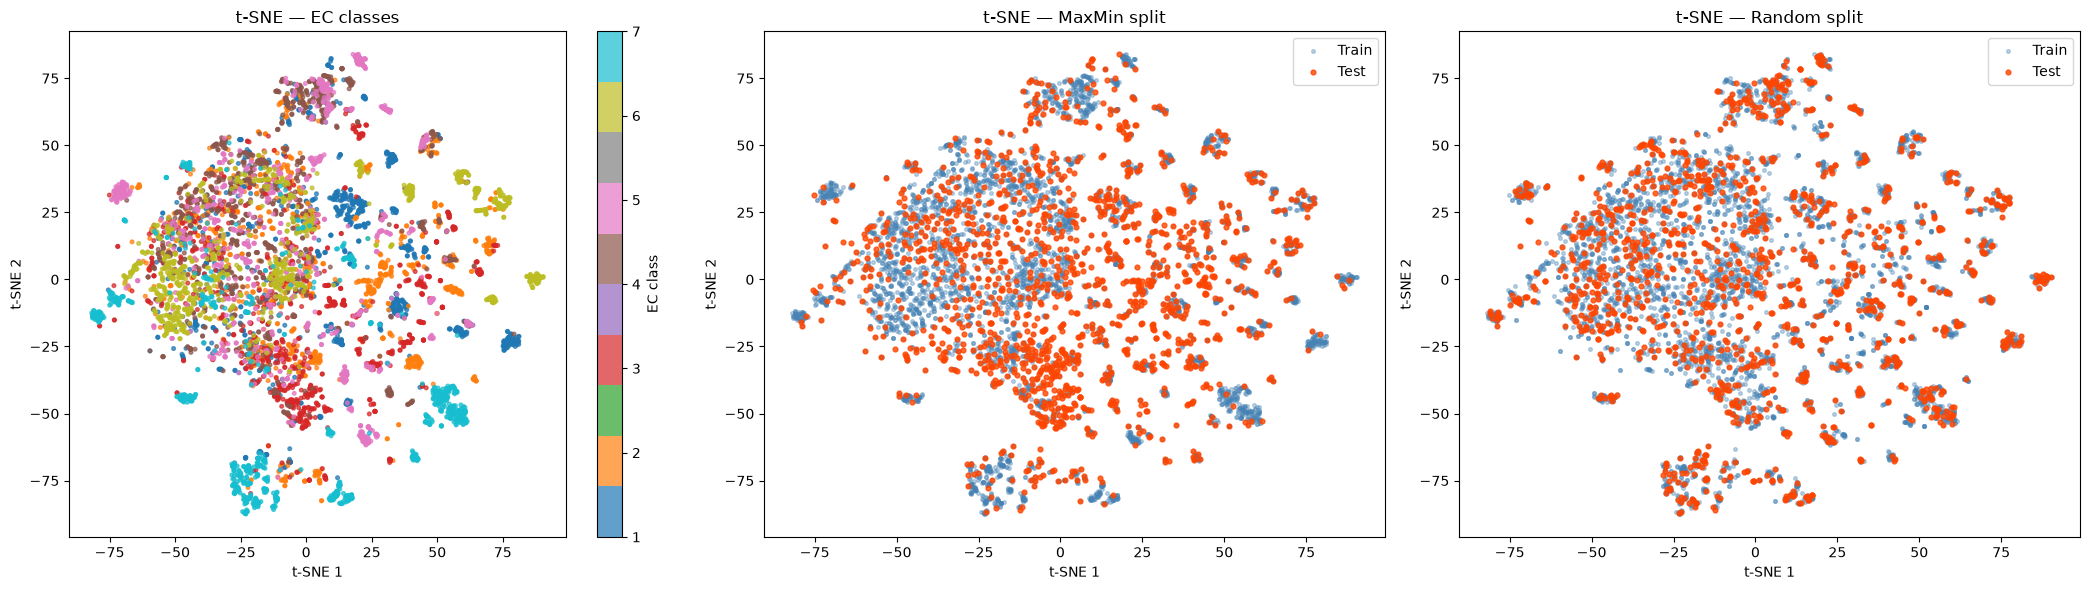

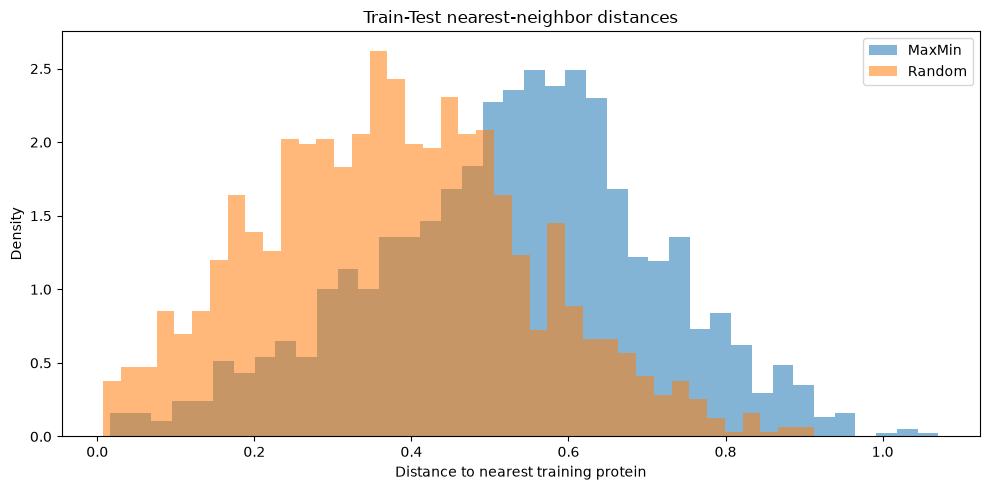

Comparison saved to: outputs


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from pathlib import Path

# ==========================================
# 1. Random split (80/20)
# ==========================================

labels = np.asarray(y)
indices = np.arange(len(labels))

random_train_idx, random_test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

print("MaxMin split:")
print(f"  Train: {len(train_idx)} | Test: {len(test_idx)}")

print("\nRandom stratified split:")
print(f"  Train: {len(random_train_idx)} | Test: {len(random_test_idx)}")


# ==========================================
# 2. Porównanie rozkładu klas EC
# ==========================================

def class_distribution(train, test, labels, method):
    rows = []

    for ec in np.unique(labels):
        rows.append({
            "Method": method,
            "EC class": ec,
            "Train": np.sum(labels[train] == ec),
            "Test": np.sum(labels[test] == ec),
            "Test %": 100 * np.mean(labels[test] == ec)
        })

    return pd.DataFrame(rows)


distribution = pd.concat([
    class_distribution(train_idx, test_idx, labels, "MaxMin"),
    class_distribution(
        random_train_idx,
        random_test_idx,
        labels,
        "Random"
    )
], ignore_index=True)

display(distribution)


# ==========================================
# 3. Odległości Test -> najbliższy Train
# ==========================================

def nearest_train_distances(X, train, test):
    nn = NearestNeighbors(
        n_neighbors=1,
        metric="euclidean",
        algorithm="auto",
        n_jobs=-1
    )

    nn.fit(X[train])

    distances, _ = nn.kneighbors(X[test])

    return distances.ravel()


maxmin_distances = nearest_train_distances(
    X_reduced, train_idx, test_idx
)

random_distances = nearest_train_distances(
    X_reduced, random_train_idx, random_test_idx
)


metrics = pd.DataFrame({
    "Method": ["MaxMin", "Random"],
    "Mean distance": [
        maxmin_distances.mean(),
        random_distances.mean()
    ],
    "Median distance": [
        np.median(maxmin_distances),
        np.median(random_distances)
    ],
    "Min distance": [
        maxmin_distances.min(),
        random_distances.min()
    ],
    "P10 distance": [
        np.percentile(maxmin_distances, 10),
        np.percentile(random_distances, 10)
    ]
})

print("\nTrain-Test distance comparison:")
display(metrics)


# ==========================================
# 4. Wizualizacja t-SNE
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# Klasy EC
sc = axes[0].scatter(
    tsne_2d[:, 0],
    tsne_2d[:, 1],
    c=labels.astype(int),
    cmap="tab10",
    s=7,
    alpha=0.7,
    rasterized=True
)

axes[0].set_title("t-SNE — EC classes")
fig.colorbar(sc, ax=axes[0], label="EC class")


def plot_split(ax, train, test, title):
    ax.scatter(
        tsne_2d[train, 0],
        tsne_2d[train, 1],
        s=7,
        alpha=0.35,
        c="steelblue",
        label="Train"
    )

    ax.scatter(
        tsne_2d[test, 0],
        tsne_2d[test, 1],
        s=12,
        alpha=0.8,
        c="orangered",
        label="Test"
    )

    ax.set_title(title)
    ax.legend()


plot_split(
    axes[1],
    train_idx,
    test_idx,
    "t-SNE — MaxMin split"
)

plot_split(
    axes[2],
    random_train_idx,
    random_test_idx,
    "t-SNE — Random split"
)

for ax in axes:
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")

plt.tight_layout()

output_dir = Path(OUTPUT_DIR)
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "maxmin_vs_random_tsne.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ==========================================
# 5. Histogram odległości Train-Test
# ==========================================

plt.figure(figsize=(10, 5))

plt.hist(
    maxmin_distances,
    bins=40,
    alpha=0.55,
    density=True,
    label="MaxMin"
)

plt.hist(
    random_distances,
    bins=40,
    alpha=0.55,
    density=True,
    label="Random"
)

plt.xlabel("Distance to nearest training protein")
plt.ylabel("Density")
plt.title("Train-Test nearest-neighbor distances")
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "maxmin_vs_random_distances.png",
    dpi=180
)

plt.show()


# ==========================================
# 6. Zapis wyników
# ==========================================

distribution.to_csv(
    output_dir / "split_class_distribution.csv",
    index=False
)

metrics.to_csv(
    output_dir / "split_distance_metrics.csv",
    index=False
)

np.savez_compressed(
    output_dir / "maxmin_vs_random_splits.npz",
    maxmin_train_idx=train_idx,
    maxmin_test_idx=test_idx,
    random_train_idx=random_train_idx,
    random_test_idx=random_test_idx
)

print("Comparison saved to:", output_dir)

## Interpretacja i dalsze eksperymenty

- **ARI ≈ 0**: zgodność z klasami EC podobna do losowej; **ARI = 1**: idealna zgodność. NMI i homogeneity uzupełniają ocenę.
- Sekwencje homologiczne i pochodzące z tych samych rodzin mogą tworzyć klastry niezależnie od EC. W kolejnym eksperymencie użyj **MMseqs2** do redukcji homologii i kontroli podobieństwa.
- Białka wielofunkcyjne występujące w wielu klasach EC zostały tu wykluczone; w osobnym eksperymencie można zastosować ewaluację wieloetykietową.
- Porównaj ESM-2 8M z większym modelem, k-mer TF-IDF i składem aminokwasowym.
- Wyniki po balansowaniu klas nie odzwierciedlają naturalnych częstości klas w Swiss-Prot.
- Na tym etapie nie ma train/test split: model ESM-2 nie jest trenowany, a klastrowanie jest bez nadzoru. Do benchmarku predykcji funkcji stosuj homology-aware split.